## 1. Load and inspect the raw data

Before writing any cleaning code, we need to know what we're actually working with: how many rows we have, what type each column is (is `genres` a plain string we'll need to split, or something else? is `summary` always text?), and where values are missing.

This matters for the RAG pipeline because `load_data.py`'s cleaning rules (dropping junk summaries, splitting genres on " | ") assume things about the data's shape. If a column has unexpected nulls or an unexpected dtype, cleaning code can fail loudly, or worse, silently do the wrong thing.

In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/cmu_books_clean.csv")

print("Shape:", df.shape)
print("\nColumn types:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isna().sum())
df.head(3)

Shape: (12055, 4)

Column types:
author     str
title      str
genres     str
summary    str
dtype: object

Missing values per column:
author     0
title      0
genres     0
summary    0
dtype: int64


,author,title,genres,summary
0,Samantha Power,"""A Problem from Hell"": America and the Age of ...",Non-fiction,Power begins with an outline of the internatio...
1,Sue Grafton,"""A"" is for Alibi",Mystery | Speculative fiction | Fiction | Susp...,"The first novel in the ""Alphabet Mysteries"" se..."
2,Sue Grafton,"""B"" Is for Burglar",Mystery | Speculative fiction | Fiction | Susp...,"In the second installment of the ""Alphabet Mys..."


In [2]:
!pip install matplotlib
!pip install tiktoken

## 2. Summary length: characters, words, and tokens

`chunking.py` decides how to split a summary based on its *token* count against `CHUNK_MAX_TOKENS` (230) and `MODEL_MAX_TOKENS` (8191) from `config.py`. Characters and words are easy sanity checks, but tokens are the number that actually drives chunking decisions, so we count them the same way the embedding model will: with tiktoken's `cl100k_base` encoding.

Looking at the distribution (min/median/90th percentile/max) tells us whether most summaries need chunking at all, or whether chunking is only relevant for a long tail of outliers. The three threshold counts (230, 512, 8191) tell us roughly how many books will actually get split, and whether any summary is anywhere near the hard model limit.

              chars         words        tokens
count  12055.000000  12055.000000  12055.000000
mean    2640.566487    452.048942    576.870261
std     2975.355084    514.649697    659.498661
min        9.000000      1.000000      2.000000
50%     1685.000000    286.000000    365.000000
90%     5938.600000   1023.000000   1304.600000
max    58018.000000  10334.000000  13835.000000

Over 230 tokens: 7681
Over 512 tokens: 4719
Over 8191 tokens: 4


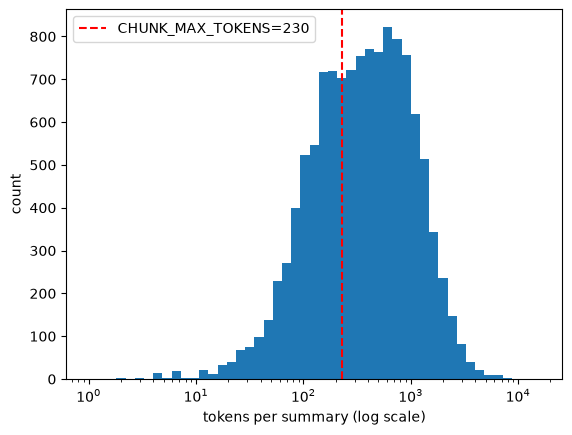

In [3]:
import tiktoken
import numpy as np
import matplotlib.pyplot as plt

enc = tiktoken.get_encoding("cl100k_base")

char_len = df["summary"].str.len()
word_len = df["summary"].str.split().str.len()
token_len = df["summary"].apply(lambda s: len(enc.encode(s)))

stats = pd.DataFrame({"chars": char_len, "words": word_len, "tokens": token_len})
print(stats.describe(percentiles=[0.5, 0.9]))

print("\nOver 230 tokens:", (token_len > 230).sum())
print("Over 512 tokens:", (token_len > 512).sum())
print("Over 8191 tokens:", (token_len > 8191).sum())

# log scale: the distribution is heavily right-skewed (a few very long
# summaries stretch a linear x-axis out to ~14,000 and squash everything else)
plt.hist(token_len, bins=np.logspace(0, 4.2, 50))
plt.xscale("log")
plt.axvline(230, color="red", linestyle="--", label="CHUNK_MAX_TOKENS=230")
plt.xlabel("tokens per summary (log scale)")
plt.ylabel("count")
plt.legend()
plt.show()

## 3. Extremes and junk markup

Reading the actual shortest and longest summaries surfaces edge cases stats alone can hide: is the shortest one a real (if terse) summary, or garbage? Is the longest one a real plot, or scraped junk?

We also count the specific junk patterns CLAUDE.md's `load_data.py` rules target: `"=="` and `"<!--"` (wiki/HTML leftovers), `"To be added."` (placeholder text), and `"|----"` (wiki table markup). Seeing the raw counts before writing the drop logic confirms these rules target real, present problems.

In [4]:
shortest = df.assign(_len=char_len).nsmallest(10, "_len")
print("=== Shortest 10 summaries ===\n")
for _, row in shortest.iterrows():
    print(f"[{row['_len']} chars] {row['title']}: {row['summary']}\n")

longest = df.assign(_len=char_len).nlargest(3, "_len")
print("\n=== Longest 3 summaries ===\n")
for _, row in longest.iterrows():
    print(f"[{row['_len']} chars] {row['title']}: {row['summary'][:500]}...\n")

has_eq = df["summary"].str.contains("==", regex=False)
has_comment = df["summary"].str.contains("<!--", regex=False)
has_table = df["summary"].str.contains("|----", regex=False)
is_tba = df["summary"].str.strip().eq("To be added.")

print("=== Junk markup counts ===")
print("Contains '==':", has_eq.sum())
print("Contains '<!--':", has_comment.sum())
print("Contains '|----':", has_table.sum())
print("Equals 'To be added.':", is_tba.sum())

=== Shortest 10 summaries ===

[9 chars] Deathstalker: - --> <!-

[9 chars] Deathstalker Destiny: - --> <!-

[9 chars] Deathstalker Honour: - --> <!-

[9 chars] Deathstalker Rebellion: - --> <!-

[9 chars] Deathstalker War: - --> <!-

[10 chars] Guardians of Ga'Hoole Book 4: The Siege: ==Receptio

[10 chars] The Caverns of Kalte: ==Receptio

[10 chars] The Deathlord of Ixia: ==Receptio

[11 chars] Chucaro: Wild Pony of the Pampa: ==Reference

[11 chars] Lurulu: ==Reference


=== Longest 3 summaries ===

[58018 chars] Kushiel's Mercy: Upon reaching the City of Elua, Sidonie and Imriel find that there are many people awaiting them. Some, like the Yeshuites and the Tsingani, are there simply because Imriel was foster-son to Phèdre nó Delaunay and Joscelin Verreuil. Also there are small knots of people, each wearing black armbands around one of their arms, signifying death. They all hold out their fists, thumbs pointed downward. Imriel later learns that these people are the families of his

## 4. Genres

Genres are how a user's request ("superpower fiction") will eventually need to connect to books, so it matters what genres actually exist, how many are common vs. rare, and how many genres a typical book carries. A genre that appears once is nearly useless for retrieval by genre name; a genre on almost every book tells us nothing distinctive.

Unique genres: 221


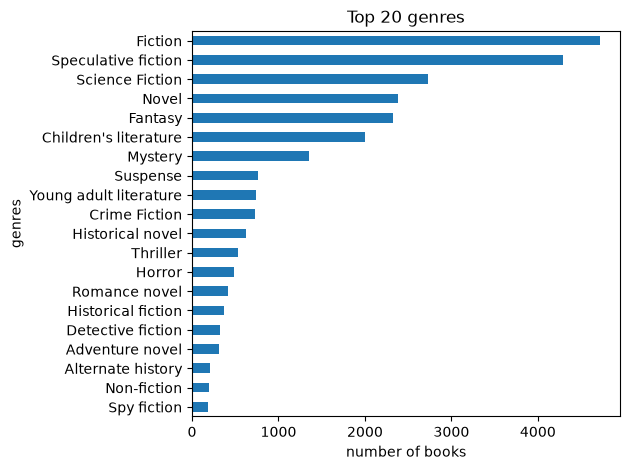


Genres per book:
count    12055.000000
mean         2.398092
std          1.411588
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         11.000000
Name: genres, dtype: float64

48 genres appear only once:
['Cabal', 'Conspiracy', 'Foreign legion', 'Elizabethan romance', 'Fictional crossover', 'Anti-war', 'Popular culture', 'Police procedural', 'Future history', 'Pastiche', 'Romantic comedy', 'Social criticism', 'Robinsonade', 'Computer Science', 'Metaphysics', 'Alien invasion', 'Georgian romance', 'Photography', 'Medieval romance', 'Superhero fiction', 'Pornography', 'Military history', 'Collage', 'Experimental literature', 'Space western', 'Fable', 'First-person narrative', 'Marketing', 'Colonial United States romance', 'Religious text', 'Low fantasy', 'Juvenile fantasy', 'American Gothic Fiction', 'Gay Themed', 'Neuroscience', 'Utopian fiction', 'New York Times Best Seller list', 'Epic Science Fiction and Fantasy', 'Fantastique', 'Human e

In [5]:
genre_lists = df["genres"].str.split(" | ", regex=False)
all_genres = genre_lists.explode()

print("Unique genres:", all_genres.nunique())

top20 = all_genres.value_counts().head(20)
top20.plot(kind="barh")
plt.gca().invert_yaxis()
plt.xlabel("number of books")
plt.title("Top 20 genres")
plt.tight_layout()
plt.show()

genres_per_book = genre_lists.str.len()
print("\nGenres per book:")
print(genres_per_book.describe())

genre_counts = all_genres.value_counts()
rare = genre_counts[genre_counts == 1]
print(f"\n{len(rare)} genres appear only once:")
print(list(rare.index))

## 5. Authors

Checking whether a handful of authors dominate the dataset matters for retrieval fairness: if one author has 50 books, their books can crowd out relevant results from other authors on generic queries. It's also a basic data-quality check — wildly inconsistent author name formatting would show up here as near-duplicate top authors.

author
Agatha Christie         72
Franklin W. Dixon       66
Edgar Rice Burroughs    56
K. A. Applegate         56
Ruth Rendell            55
John Dickson Carr       55
Stephen King            53
Orson Scott Card        47
Dean Koontz             47
P. G. Wodehouse         45
Name: count, dtype: int64


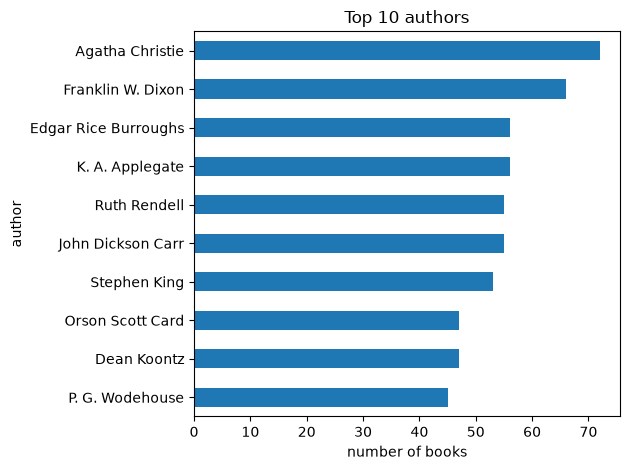

In [6]:
top_authors = df["author"].value_counts().head(10)
print(top_authors)

top_authors.plot(kind="barh")
plt.gca().invert_yaxis()
plt.xlabel("number of books")
plt.title("Top 10 authors")
plt.tight_layout()
plt.show()

## 6. Duplicates

CLAUDE.md's `load_data.py` rules drop exact duplicate summaries and duplicate (title, author) pairs. Before trusting that logic, we look at real examples: are duplicate titles usually the *same* book (a true duplicate to drop) or different books that happen to share a title (a false positive our rule correctly does NOT drop, since it also checks author)?

In [7]:
dup_titles = df[df.duplicated("title", keep=False)].sort_values("title")
dup_title_author = df[df.duplicated(["title", "author"], keep=False)].sort_values(["title", "author"])
dup_summary = df[df.duplicated("summary", keep=False)].sort_values("summary")

print("Duplicate titles (any author):", df["title"].duplicated().sum())
print("Duplicate (title, author) pairs:", df.duplicated(["title", "author"]).sum())
print("Duplicate summaries:", df["summary"].duplicated().sum())

print("\n=== Example duplicate titles ===")
print(dup_titles[["title", "author"]].head(10).to_string())

print("\n=== Example duplicate (title, author) pairs ===")
print(dup_title_author[["title", "author"]].head(10).to_string())

print("\n=== Example duplicate summaries ===")
print(dup_summary[["title", "author"]].head(10).to_string())

Duplicate titles (any author): 179
Duplicate (title, author) pairs: 3
Duplicate summaries: 24

=== Example duplicate titles ===
                 title                author
38                1945         Robert Conroy
39                1945  William R. Forstchen
97              A Casa          Andre Vianco
98              A Casa     Miguel M. Abrahão
396  A Taste for Death           P. D. James
397  A Taste for Death       Peter O'Donnell
453          Abduction            Peg Kehret
454          Abduction            Robin Cook
798          Archangel          Sharon Shinn
797          Archangel         Robert Harris

=== Example duplicate (title, author) pairs ===
                               title            author
2643                    Ender's Game  Orson Scott Card
2644                    Ender's Game  Orson Scott Card
5091  Mr. Monk Goes to the Firehouse      Lee Goldberg
5092  Mr. Monk Goes to the Firehouse      Lee Goldberg
8983                        The Keep    F. Paul Wilso

## 7. Keyword check

A direct sanity check against the app's own example query ("recommend some superpower fiction books"): does the dataset actually contain relevant books? If none matched, we'd know before spending any embedding budget that either the dataset lacks this content or the query needs to be phrased differently (e.g. via genre/synonym matching rather than exact keywords).

In [8]:
keywords = ["superpower", "superhero", "mutant"]
pattern = "|".join(keywords)
matches = df[df["summary"].str.contains(pattern, case=False, na=False, regex=True)]

print(f"Summaries containing {keywords}: {len(matches)}")
print("\n5 example titles:")
print(matches["title"].head(5).to_list())

Summaries containing ['superpower', 'superhero', 'mutant']: 92

5 example titles:
['A Canticle for Leibowitz', 'Across the Sea of Suns', 'Angel: A Maximum Ride Novel', "Armageddon's Children", 'Ballroom of the Skies']
